# 07 - Is the connectome an inhibition-stabilized network, and can it respond paradoxically?

Implements `docs/ISN_PARADOX_PLAN.md`. All analysis code lives in
`isn_paradox.py`; this notebook only sets parameters, calls one helper per step,
and shows the result. Edit the module, not the cells, when a method changes.

**Model.** $\tau\,\dot x = -x + gWx + b$, with $W = M[\text{post},\text{pre}]$ scaled to
spectral radius 1, so the global gain $g$ is the only free scale.
Steady-state response: $\Gamma = (I - gW)^{-1}$.

| Property | Test |
|---|---|
| ISN | $\alpha(gW_{EE}) > 1 > \alpha(gW)$, where $\alpha$ is the max real part of the eigenvalues |
| Self-paradox of type $k$ | $\Gamma_{kk} < 0$ |
| Class paradox | summed own response of a driven set $S$ is $< 0$ (basis-dependent) |

**Key identity.** $\Gamma_{kk} = \det(I - gW_{-k}) / \det(I - gW)$, so type $k$ is
paradoxical **iff the network with $k$ clamped is unstable** (odd number of
real eigenvalues of $gW_{-k}$ above 1). ISN asks whether inhibition *as a whole*
stabilises E; self-paradox asks whether *one type* is indispensable.

**Conventions.** Orientation is verified at load by the Dale's-law oracle.
Blocks are named source → target (`e_to_i`, `i_to_e`), never bare `EI`.
Every result is reported for `with_self` and `no_self`. Magnitudes are
conditional on $g$, so verdicts are given as functions of $g$.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import isn_paradox as ip
import jacobian_core as jc

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

OUT = jc.output_dir("07_isn_paradox")
save = lambda df, name: jc.save_table(df, OUT, name)

net = ip.load_network("matrices/mij_matrix.csv", "matrices/mij_netlist.csv")
VARIANTS = net.variants                      # with_self / no_self, each rho(W) = 1
SETS = ip.class_sets(net)                    # all_I, class:*, region:*, region:class
CLASS_SETS = {k: v for k, v in SETS.items() if k == "all_I" or k.startswith(("class:", "region:"))}

# Reference gains: inside each variant's ISN window (Phase 1 shows where that is).
# These are working values until Phase 1.3 supplies a principled operating point.
G_REF = {"with_self": 0.98, "no_self": 0.95}
GAINS = np.round(np.arange(0.50, 0.9995, 0.0025), 4)
MARGIN = 0.01   # paradox onsets within 1% of g_full are treated as trivial near-critical effects
print(f"{net.n} types: {net.E.sum()} E, {net.I.sum()} I; orientation check: {net.data.orientation_check}")

85 types: 32 E, 53 I; orientation check: {'E_to_I_positive': 1.0, 'I_to_E_negative': 1.0, 'n_excitatory': 32.0, 'n_inhibitory': 53.0}


Interneuron classes come from keyword rules on Hippocampome type names
(`ip.I_CLASS_RULES`). Check this table, and edit the rules in the module if a
type is misassigned.

In [2]:
display(net.meta.query("ei == 'i'").groupby("i_class").apply(lambda d: ", ".join(d.index)).to_frame("types"))

,types
i_class,
OLM_like,"CA1 O LM, CA1 O LMR, CA1 OR LM, CA1 Oriens Alv..."
axo_axonic,"CA1 Axo Axonic, CA1 Horizontal Axo Axonic, CA3..."
basket,"CA1 Basket, CA1 Horizontal Basket, CA2 Basket,..."
basket_CCK,"CA1 Basket CCK+, CA3 Basket CCK+"
bistratified,"CA1 Bistratified, CA1 Oriens Bistratified, CA2..."
dendrite_targeting,"CA1 LMR, CA1 Perforant Path Associated, CA1 Pe..."
neurogliaform_ivy,"CA1 Ivy, CA1 Neurogliaform, CA1 Neurogliaform ..."
other,"MEC LIII Superficial Multipolar Interneuron, M..."
projecting,"CA1 Back Projection, CA1 Radial Trilaminar, CA..."


## Phase 1 - Operating point

ISN status is a property of the gain, so this phase comes first.

### 1.1 What the raw operator implies

`g_raw` is the factor that turns the unit-ρ matrix back into raw $M$. If $M$ were
in rate-to-rate units this would be the operating point. A value far above
`g_full` means a scale factor is missing from the raw units.

In [3]:
raw = ip.raw_gain_report(net)
save(raw, "raw_gain_report"); raw

,raw_rho,g_raw,alpha_full,alpha_EE,g_E,g_full,window_exists,window_width,window_relative
variant,,,,,,,,,
with_self,26213.1301,26213.1301,1.0,1.0419,0.9598,1.0,True,0.0402,0.0402
no_self,14837.8659,14837.8659,1.0,1.1716,0.8535,1.0,True,0.1465,0.1465


### 1.2 Gain sweep and ISN window

$\alpha(gW)$ (full), $\alpha(gW_{EE})$ (inhibition clamped) and $\alpha(W_{\text{eff}})$
(inhibition eliminated by the Schur complement
$W_{\text{eff}} = gW_{e\to e} + gW_{i\to e}(I - gW_{i\to i})^{-1} gW_{e\to i}$).
The shaded band is the ISN window. Dotted lines mark the project's usual
normalisations, 0.85 and 0.95.

,alpha_full,alpha_EE,g_E,g_full,window_exists,window_width,window_relative
with_self,1.0,1.0419,0.9598,1.0,True,0.0402,0.0402
no_self,1.0,1.1716,0.8535,1.0,True,0.1465,0.1465


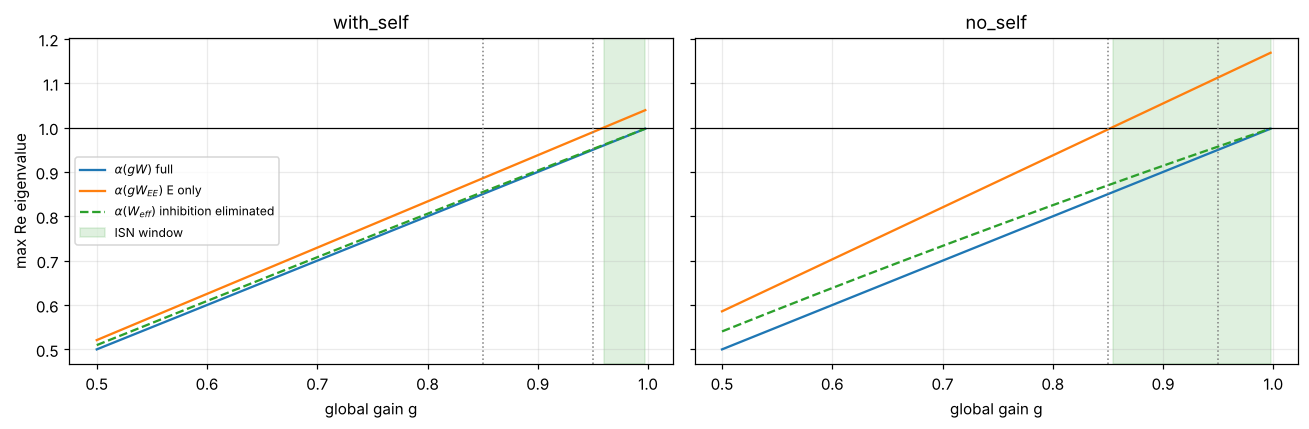

In [4]:
sweeps = {v: ip.gain_sweep(W, net.E, net.I, GAINS) for v, W in VARIANTS.items()}
windows = pd.DataFrame({v: ip.isn_window(W, net.E) for v, W in VARIANTS.items()}).T
for v, df in sweeps.items():
    save(df, f"gain_sweep_{v}")
save(windows, "isn_windows")
ip.plot_gain_sweep(sweeps); plt.tight_layout(); plt.savefig(OUT / "gain_sweep.png", bbox_inches="tight")
windows

### 1.3 Principled gain - TODO

The window is narrow and sits next to the arbitrary normalisation constants, so
the verdict depends on obtaining $g$ independently. Options, in order:

1. Restore physical units in $m_{ij}$ ($q\cdot c\cdot g\cdot\Delta V\cdot\tau\cdot\kappa$) and work out
   what is missing for a rate-to-rate loop gain (e.g. per-postsynaptic-population
   normalisation).
2. Calibrate to an observable: in-vivo baseline rates, or the E-only
   instability seen in slices with GABA_A blocked.
3. Failing both, report the verdict as a function of $g$ (as below).

Set `G_REF` in the setup cell when a principled value exists.

## Phase 2 - ISN test

### 2.1 Which excitatory assembly is unstable

Right (activity pattern) and left (input sensitivity) loadings of the leading
eigenvector of $W_{EE}$.

In [5]:
e_labels = [x for x, e in zip(net.labels, net.E) if e]
for v, W in VARIANTS.items():
    mode = ip.leading_mode(W[np.ix_(net.E, net.E)], e_labels, top=8)
    print(f"{v}: leading eigenvalue of W_EE = {mode.attrs['eigenvalue'].real:.4f}")
    display(mode)

with_self: leading eigenvalue of W_EE = 1.0419


,right_loading,left_loading
cell_type,,
MEC LIII Bipolar Complex Pyramidal,0.0688,0.0035
EC LIII Stellate,0.0658,0.0005
EC LII III Pyramidal Tripolar,0.0628,0.1071
MEC LII Stellate,0.0568,0.0341
MEC LII III Pyramidal Multiform,0.0519,0.0042
EC LIII Pyramidal,0.0519,0.0003
MEC LIII Complex Pyramidal,0.0510,0.0149
EC LI II Multipolar Pyramidal,0.0501,0.5731


no_self: leading eigenvalue of W_EE = 1.1716


,right_loading,left_loading
cell_type,,
DG Mossy,0.0869,9.0882e-04
CA1 Pyramidal,0.0823,1.1282e-02
MEC LV VI Pyramidal Polymorphic,0.0808,2.8236e-05
DG Hilar Ectopic Granule,0.0683,4.1426e-07
LEC LVI Multipolar Pyramidal,0.0569,7.5945e-04
EC LV Deep Pyramidal,0.0410,5.7888e-04
CA2 Pyramidal,0.0378,1.9216e-02
EC LIII V Bipolar Pyramidal,0.0370,5.3336e-03


### 2.2 Regional ISN

Region-restricted E subnetworks. `local_ISN_window` = the region's E types
destabilise before both the region's full subnetwork and the whole network do.
`EC-all superficial/deep` pools EC, MEC and LEC by layer.

In [6]:
regional = {v: ip.regional_isn(net, W, G_REF[v]) for v, W in VARIANTS.items()}
for v, df in regional.items():
    save(df, f"regional_isn_{v}"); print(v); display(df)

with_self


,n_E,n_I,g_E_region,g_region_full,local_ISN_window,local_ISN_at_g=0.98
region,,,,,,
EC-all superficial,14,2,0.9676,1.0071,True,True
EC,9,0,1.0569,1.0569,False,False
DG,4,10,3.4678,657.2194,False,False
MEC,9,2,5.9909,10.0850,False,False
CA3,3,11,6.4865,14.4114,False,False
CA1,2,26,9.3828,26.2096,False,False
EC-all deep,7,0,9.7818,9.7818,False,False
CA2,1,4,12.1181,17.9363,False,False
LEC,3,0,19.7962,19.7962,False,False


no_self


,n_E,n_I,g_E_region,g_region_full,local_ISN_window,local_ISN_at_g=0.95
region,,,,,,
EC-all superficial,14,2,0.9321,1.0866,True,True
EC,9,0,1.1909,1.1909,False,False
DG,4,10,2.2389,10.2730,False,False
MEC,9,2,3.9383,7.9883,False,False
CA3,3,11,9.2067,8.9042,False,False
EC-all deep,7,0,11.0964,11.0964,False,False
LEC,3,0,21.0797,21.0797,False,False
CA2,1,4,inf,40.4755,False,False
SUB,1,0,inf,inf,False,False


### 2.3 Which inhibition stabilises: clamp screen at `G_REF`

Clamp (remove) each interneuron class or region. `unstable_after_clamp` means
that set is necessary for stability. With `odd_real_crossings`, the set is also
paradoxical by the determinant identity.

In [7]:
for v, W in VARIANTS.items():
    df = ip.clamp_screen(net, W, G_REF[v], CLASS_SETS)
    save(df, f"clamp_screen_{v}"); print(f"{v}, g = {G_REF[v]}"); display(df.head(12))

with_self, g = 0.98


,n_types,alpha_after_clamp,unstable_after_clamp,n_real_eigs_gt_1,odd_real_crossings
clamped,,,,,
all_I,53,1.0211,True,1,True
region:MEC,2,1.0196,True,1,True
class:other,2,1.0196,True,1,True
region:CA1,26,0.9808,False,0,False
class:basket,7,0.9807,False,0,False
region:CA3,11,0.9805,False,0,False
class:projecting,4,0.9803,False,0,False
class:basket_CCK,2,0.9803,False,0,False
region:CA2,4,0.9802,False,0,False


no_self, g = 0.95


,n_types,alpha_after_clamp,unstable_after_clamp,n_real_eigs_gt_1,odd_real_crossings
clamped,,,,,
all_I,53,1.1131,True,1,True
region:MEC,2,1.0689,True,1,True
class:other,2,1.0689,True,1,True
class:basket,7,0.9830,False,0,False
region:CA1,26,0.9753,False,0,False
region:CA3,11,0.9670,False,0,False
region:DG,10,0.9630,False,0,False
class:projecting,4,0.9623,False,0,False
class:basket_CCK,2,0.9580,False,0,False


### 2.4 Attribution of the stabilising shift

First-order shift of the leading eigenvalue of $gW_{e\to e}$ caused by each I
type through the Schur complement (negative = stabilising). `direct_loop_gain`
keeps only the direct E→I$_k$→E loop, without I→I relays.

In [8]:
for v, W in VARIANTS.items():
    sc = ip.stabilizer_contributions(net, W, G_REF[v])
    save(sc, f"stabilizer_contributions_{v}")
    print(f"{v}: lambda(gW_EE) = {sc.attrs['lambda_EE']:.4f} -> alpha(W_eff) = {sc.attrs['alpha_E_eff_exact']:.4f} "
          f"(first-order total {sc.attrs['first_order_total']:+.4f})")
    display(sc.head(8))

with_self: lambda(gW_EE) = 1.0211 -> alpha(W_eff) = 0.9807 (first-order total -0.0407)


,first_order_shift,direct_loop_gain,i_class,region
cell_type,,,,
MEC LIII Superficial Multipolar Interneuron,-0.0337,-0.0398,other,MEC
MEC LIII Superficial Trilayered Interneuron,-0.0052,-0.0056,other,MEC
CA3 Basket,-0.0004,-0.0004,basket,CA3
CA1 Back Projection,-0.0003,-0.0003,projecting,CA1
CA2 Wide Arbor Basket,-0.0002,-0.0002,basket,CA2
CA1 Basket CCK+,-0.0002,-0.0002,basket_CCK,CA1
CA3 Basket CCK+,-0.0002,-0.0002,basket_CCK,CA3
CA1 Trilaminar,-0.0001,-0.0001,projecting,CA1


no_self: lambda(gW_EE) = 1.1131 -> alpha(W_eff) = 0.9574 (first-order total -0.1619)


,first_order_shift,direct_loop_gain,i_class,region
cell_type,,,,
MEC LIII Superficial Multipolar Interneuron,-0.0863,-0.0871,other,MEC
CA1 Back Projection,-0.0126,-0.0137,projecting,CA1
CA3 Basket,-0.0107,-0.0133,basket,CA3
DG AIPRIM,-0.0102,-0.0105,basket,DG
MEC LIII Superficial Trilayered Interneuron,-0.0087,-0.0102,other,MEC
CA2 Wide Arbor Basket,-0.0081,-0.0088,basket,CA2
CA1 Basket CCK+,-0.0046,-0.0053,basket_CCK,CA1
CA3 Basket CCK+,-0.0038,-0.0067,basket_CCK,CA3


## Phase 3 - Paradoxical responses

### 3.1 Check the determinant identity

$\Gamma_{kk} < 0 \iff$ odd number of real eigenvalues of $gW_{-k}$ above 1, for every I type
and several gains. Raises if it ever fails.

In [9]:
for v, W in VARIANTS.items():
    print(v, ip.verify_cramer(net, W, [0.8, 0.9, 0.95, G_REF[v], 0.99]).mismatches.sum(), "mismatches")

with_self 0 mismatches


no_self 0 mismatches


### 3.2 Onset gain of self-paradox per type

Exact onset from the clamped spectrum. Close to $g_{\text{full}}$,
$\Gamma \approx v u^\top / (1 - g/g_{\text{full}})$, so every type with $u_k v_k < 0$ goes
paradoxical in a thin sliver. `robust_paradox` excludes onsets within `MARGIN`
of $g_{\text{full}}$.

,with_self,no_self
any (< g_full),52,52
robust,1,4


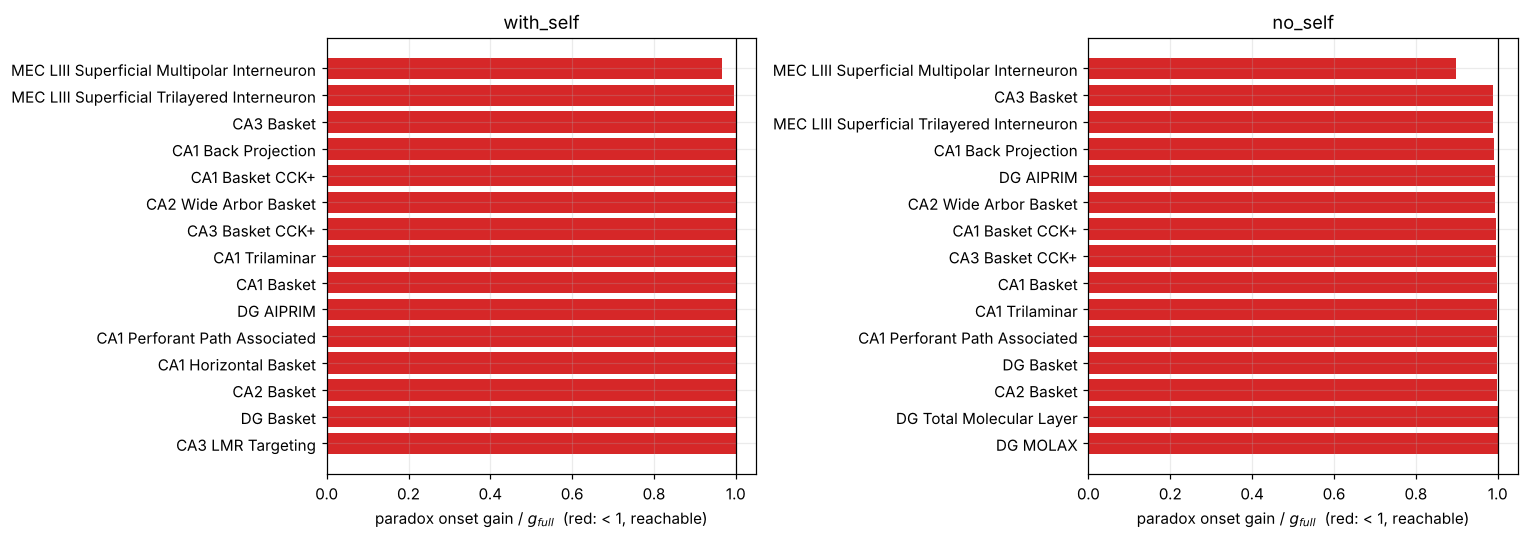

In [10]:
onsets = {v: ip.paradox_onsets(net, W, margin=MARGIN) for v, W in VARIANTS.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (v, df) in zip(axes, onsets.items()):
    save(df, f"paradox_onsets_{v}"); ip.plot_onsets(df, ax=ax); ax.set_title(v)
plt.tight_layout(); plt.savefig(OUT / "paradox_onsets.png", bbox_inches="tight")
pd.DataFrame({v: {"any (< g_full)": df.paradoxical_before_g_full.sum(), "robust": df.robust_paradox.sum()}
              for v, df in onsets.items()})

### 3.3 Class-level responses (optogenetic analogue)

Drive a whole class or region; sum the response of the driven types. Class sums
are **basis-dependent**: `uniform` drives every type equally, `census` scales the
drive by $q$. $\Gamma_{kk}$ (3.2) is basis-invariant.

In [11]:
for v, W in VARIANTS.items():
    for basis in ("uniform", "census"):
        df = ip.class_response_table(net, W, G_REF[v], CLASS_SETS, basis=basis)
        save(df, f"class_response_{v}_{basis}")
        print(f"{v}, g = {G_REF[v]}, basis = {basis}: {df.class_paradox.sum()} paradoxical sets")
        display(df[df.class_paradox | (df.n_members_negative > 0)].head(10))

with_self, g = 0.98, basis = uniform: 3 paradoxical sets


,n_types,own_response_sum,own_response_mean,n_members_negative,E_response_sum,class_paradox
set,,,,,,
region:MEC,2,-3.5643,-1.7821,1,-5.1090,True
class:other,2,-3.5643,-1.7821,1,-5.1090,True
all_I,53,-2.4518,-0.0463,15,-7.5385,True


with_self, g = 0.98, basis = census: 3 paradoxical sets


,n_types,own_response_sum,own_response_mean,n_members_negative,E_response_sum,class_paradox
set,,,,,,
all_I,53,-13.6109,-0.2568,30,-8.0303,True
class:other,2,-4.4317,-2.2159,1,-6.3525,True
region:MEC,2,-4.4317,-2.2159,1,-6.3525,True
class:projecting,4,2.0735,0.5184,1,-0.2642,False
class:basket,7,5.0297,0.7185,1,-0.4516,False
region:CA3,11,5.8641,0.5331,2,-0.4285,False
class:OLM_like,8,7.1282,0.8910,1,-0.2401,False
region:CA1,26,10.0599,0.3869,5,-0.4026,False
class:dendrite_targeting,17,10.3373,0.6081,3,-0.4650,False


no_self, g = 0.95, basis = uniform: 5 paradoxical sets


,n_types,own_response_sum,own_response_mean,n_members_negative,E_response_sum,class_paradox
set,,,,,,
all_I,53,-178.3627,-3.3653,38,-20.0090,True
class:other,2,-4.3155,-2.1578,1,-7.2016,True
region:MEC,2,-4.3155,-2.1578,1,-7.2016,True
class:basket,7,-1.3189,-0.1884,3,-4.6587,True
class:basket_CCK,2,-0.1300,-0.0650,1,-4.9806,True
class:projecting,4,0.8500,0.2125,1,-1.3780,False
region:DG,10,5.1952,0.5195,2,-1.1777,False
region:CA3,11,7.0709,0.6428,1,-7.8083,False
region:CA1,26,8.9019,0.3424,4,-2.0965,False


no_self, g = 0.95, basis = census: 5 paradoxical sets


,n_types,own_response_sum,own_response_mean,n_members_negative,E_response_sum,class_paradox
set,,,,,,
all_I,53,-144.2227,-2.7212,38,-16.6259,True
class:other,2,-5.3659,-2.6829,1,-8.9543,True
region:MEC,2,-5.3659,-2.6829,1,-8.9543,True
region:CA1,26,-0.8346,-0.0321,13,-1.6354,True
class:projecting,4,-0.4291,-0.1073,1,-1.3879,True
region:DG,10,1.6650,0.1665,5,-3.4984,False
class:basket,7,2.1096,0.3014,4,-2.0205,False
class:dendrite_targeting,17,4.3369,0.2551,9,-1.8040,False
region:CA3,11,4.9207,0.4473,4,-2.4093,False


### 3.4 Paradox vs disinhibition

Each set's own response split into `direct` + `via_I_to_I` (inhibitory-only
network, with $W_{e\to i}$ cut) + `via_E_loop` (the rest). A negative total that
disappears without the E loop is an ISN-type paradox. A negative
inhibitory-only response is disinhibition.

The second call is deliberately **outside** the strict ISN window (no_self at
g = 0.85, just below $g_E = 0.854$). Class-level paradox can still appear there,
because class sums are not tied to E-subnetwork instability the way
$\Gamma_{kk}$ is.

In [12]:
for v, g in [("with_self", G_REF["with_self"]), ("no_self", G_REF["no_self"]), ("no_self", 0.85)]:
    df = ip.path_decomposition(net, VARIANTS[v], g, CLASS_SETS)
    save(df, f"path_decomposition_{v}_g{g}"); print(f"{v}, g = {g}"); display(df.head(8))

with_self, g = 0.98


,direct,via_I_to_I,via_E_loop,total,verdict
set,,,,,
region:MEC,2.0,-0.2377,-5.3265,-3.5643,ISN-type paradox (needs E loop)
class:other,2.0,-0.2377,-5.3265,-3.5643,ISN-type paradox (needs E loop)
all_I,53.0,-3.9970,-51.4549,-2.4518,ISN-type paradox (needs E loop)
class:basket_CCK,2.0,-0.0807,-0.3528,1.5665,not paradoxical
class:bistratified,3.0,-0.0105,-0.0022,2.9873,not paradoxical
class:projecting,4.0,-0.0894,-0.5921,3.3186,not paradoxical
region:CA2,4.0,-0.1384,-0.1528,3.7088,not paradoxical
class:axo_axonic,5.0,0.0000,-0.0145,4.9855,not paradoxical


no_self, g = 0.95


,direct,via_I_to_I,via_E_loop,total,verdict
set,,,,,
all_I,53.0,-5.8185,-225.5442,-178.3627,ISN-type paradox (needs E loop)
class:other,2.0,-0.1704,-6.1451,-4.3155,ISN-type paradox (needs E loop)
region:MEC,2.0,-0.1704,-6.1451,-4.3155,ISN-type paradox (needs E loop)
class:basket,7.0,-0.3237,-7.9952,-1.3189,ISN-type paradox (needs E loop)
class:basket_CCK,2.0,0.0176,-2.1475,-0.1300,ISN-type paradox (needs E loop)
class:projecting,4.0,-0.1175,-3.0325,0.8500,not paradoxical
region:CA2,4.0,-0.1804,-0.9856,2.8340,not paradoxical
class:bistratified,3.0,0.0007,-0.0144,2.9863,not paradoxical


no_self, g = 0.85


,direct,via_I_to_I,via_E_loop,total,verdict
set,,,,,
all_I,53.0,-5.2629,-82.6356,-34.8985,ISN-type paradox (needs E loop)
class:other,2.0,-0.1527,-1.7283,0.1190,not paradoxical
region:MEC,2.0,-0.1527,-1.7283,0.1190,not paradoxical
class:basket_CCK,2.0,0.0141,-0.9925,1.0216,not paradoxical
class:projecting,4.0,-0.1062,-1.3656,2.5281,not paradoxical
class:bistratified,3.0,0.0005,-0.0040,2.9964,not paradoxical
class:basket,7.0,-0.2953,-3.3041,3.4006,not paradoxical
region:CA2,4.0,-0.1619,-0.4044,3.4337,not paradoxical


### 3.5 Two-population reduction

Mean-field 2×2 collapse (uniform weighting) and the classic conditions. If the
full network is an ISN but the reduction is not, the ISN property lives in
specific types, not in the E/I averages.

In [13]:
pd.DataFrame({v: ip.two_population_reduction(net, W, G_REF[v]) for v, W in VARIANTS.items()})

,with_self,no_self
w_EtoE,0.989,1.6599
w_ItoE,-0.0133,-0.0235
w_EtoI,8.1492,14.3968
w_ItoI,-0.0849,-0.1289
g,0.98,0.95
E_alone_unstable (g w_EE > 1),False,True
E-I-E loop gain,0.104,0.3051
loop gain needed,-0.0333,0.6475
trace<0,True,True
det>0,True,False


### 3.6 Transient signature

Exact linear response to a step of drive. The textbook ISN signature is an
initial rise followed by a fall below baseline. The size of the rise reflects
the non-normal E→I amplification. The run length scales with the slowest mode,
which is long near $g_{\text{full}}$.

with_self


,peak,t_peak,final,t_zero_cross,shape
MEC LIII Superficial Multipolar Interneuron,0.7828,3.1,-0.6072,45.25,rise-then-dip (ISN signature)
all_I,38.4363,2.25,-2.3666,132.1,rise-then-dip (ISN signature)


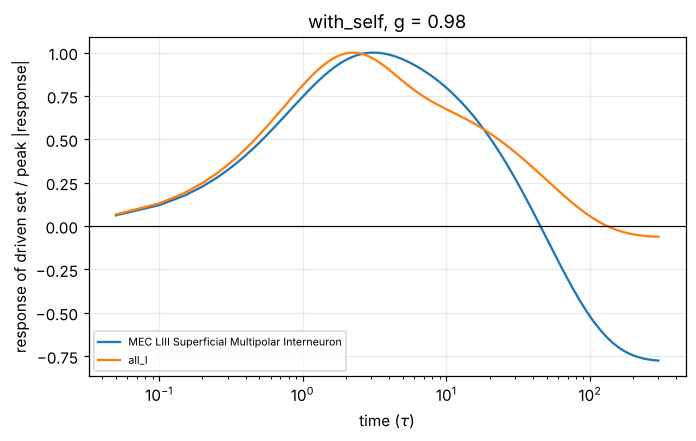

no_self


,peak,t_peak,final,t_zero_cross,shape
MEC LIII Superficial Multipolar Interneuron,0.8128,2.5,-1.2103,13.65,rise-then-dip (ISN signature)
all_I,29.5999,1.35,-177.8663,3.9,rise-then-dip (ISN signature)


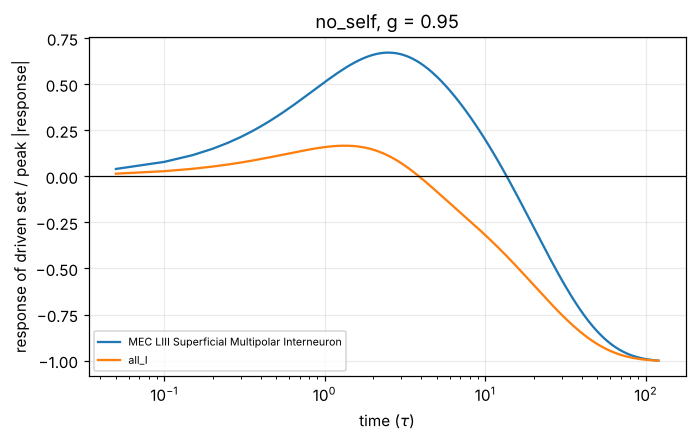

In [14]:
# Targets: types already paradoxical at G_REF (onset below it), plus all-I drive.
at_ref = {v: df.index[df.robust_paradox & (df.onset_gain < G_REF[v])] for v, df in onsets.items()}
steps = {}
for v, W in VARIANTS.items():
    targets = {k: [k] for k in at_ref[v]}
    targets["all_I"] = SETS["all_I"]
    table, traces = ip.step_response_table(net, W, G_REF[v], targets)
    steps[v] = table; save(table, f"step_signature_{v}")
    print(v); display(table)
    ip.plot_step_responses(traces); plt.title(f"{v}, g = {G_REF[v]}")
    plt.savefig(OUT / f"step_responses_{v}.png", bbox_inches="tight"); plt.show()

## Phase 4 - Robustness

All summaries in this phase are normalisation-free: `g_E_over_g_full` (< 1 means
an ISN window exists; smaller means wider) and the robustly paradoxical set.

### 4.1 Weights vs topology

Surrogates from `docs/WEIGHTS_VS_TOPOLOGY.md`: is the ISN window built by the
wiring, the census $q$, or the gain $\kappa$?

In [15]:
prof = {v: ip.profile_table(net, ip.surrogate_operators(net, v)) for v in VARIANTS}
for v, df in prof.items():
    save(df, f"surrogate_profiles_{v}"); print(v)
    display(df[["window_exists", "g_E_over_g_full", "n_paradoxical_any", "n_paradoxical_robust",
                "first_paradoxical", "first_onset_over_g_full"]])

with_self


,window_exists,g_E_over_g_full,n_paradoxical_any,n_paradoxical_robust,first_paradoxical,first_onset_over_g_full
M,True,0.9598,52,1,MEC LIII Superficial Multipolar Interneuron,0.9665
binary_sign,True,0.882,28,2,MEC LIII Superficial Multipolar Interneuron,0.9406
M/kappa,True,0.9618,50,1,CA2 Wide Arbor Basket,0.9888
M/q,True,0.5301,3,3,MEC LIII Superficial Multipolar Interneuron,0.5685
M/(kappa q),True,0.6139,32,5,CA3 Basket CCK+,0.909


no_self


,window_exists,g_E_over_g_full,n_paradoxical_any,n_paradoxical_robust,first_paradoxical,first_onset_over_g_full
M,True,0.8535,52,4,MEC LIII Superficial Multipolar Interneuron,0.8988
binary_sign,True,0.8509,27,2,MEC LIII Superficial Multipolar Interneuron,0.9228
M/kappa,True,0.9494,51,2,CA2 Wide Arbor Basket,0.9848
M/q,False,6.7349,29,0,,NaN
M/(kappa q),False,2.3019,3,2,CA2 Basket,0.9645


### 4.2 κ and q uncertainty

Lognormal jitter on κ (rows, postsynaptic) and q (columns, presynaptic).
About 2 minutes for 6 × 200 draws.

In [16]:
jit = {}
for v in VARIANTS:
    for label, sk, sq in [("kappa", 0.3, 0.0), ("q", 0.0, 0.3), ("both", 0.3, 0.3)]:
        jit[(v, label)] = ip.jitter_ensemble(net, v, sigma_kappa=sk, sigma_q=sq, n=200, seed=1)
summary = pd.DataFrame({
    k: {"P(ISN window)": df.window_exists.mean(),
        "g_E/g_full median": df.g_E_over_g_full.median(),
        "P(>=1 robust paradox)": (df.n_paradoxical_robust > 0).mean(),
        "modal first paradoxical": df.first_paradoxical.replace("", np.nan).mode().iat[0]
        if df.first_paradoxical.ne("").any() else ""}
    for k, df in jit.items()}).T
save(summary, "jitter_summary"); summary

P(ISN window) g_E/g_full median P(>=1 robust paradox)                      modal first paradoxical
with_self kappa           1.0            0.9577                   1.0  MEC LIII Superficial Multipolar Interneuron
          q               1.0            0.9573                   1.0  MEC LIII Superficial Multipolar Interneuron
          both            1.0            0.9564                 0.995  MEC LIII Superficial Multipolar Interneuron
no_self   kappa           1.0            0.8454                   1.0  MEC LIII Superficial Multipolar Interneuron
          q               1.0            0.8451                   1.0  MEC LIII Superficial Multipolar Interneuron
          both            1.0            0.8393                   1.0  MEC LIII Superficial Multipolar Interneuron

### 4.3 Null ensembles

- `block_weight_shuffle`: same topology and signs; weights shuffled within each E/I block.
- `degree_dyad_rewire`: in/out-degree and mutual/asymmetric dyad census preserved
  (`motif_analysis/weighted_motif_null.py`). Dale's law is re-imposed from the
  source; the diagonal is kept. About 2 s per draw (the cell takes about 2 minutes);
  increase `n` for final numbers. With n = 20 the smallest attainable p is 1/21 ≈ 0.048.

,variant,null,n,observed g_E/g_full,null median,P(null window exists),p (window narrower in observed),observed n robust paradox,null mean n robust paradox
0,with_self,block_weight_shuffle,100,0.9598,0.9573,1.00,0.5347,1,1.28
1,with_self,degree_dyad_rewire,20,0.9598,1.8223,0.15,0.1905,1,2.40
2,no_self,block_weight_shuffle,100,0.8535,0.9491,1.00,0.1881,4,1.48
3,no_self,degree_dyad_rewire,20,0.8535,2.3974,0.10,0.0476,4,2.70


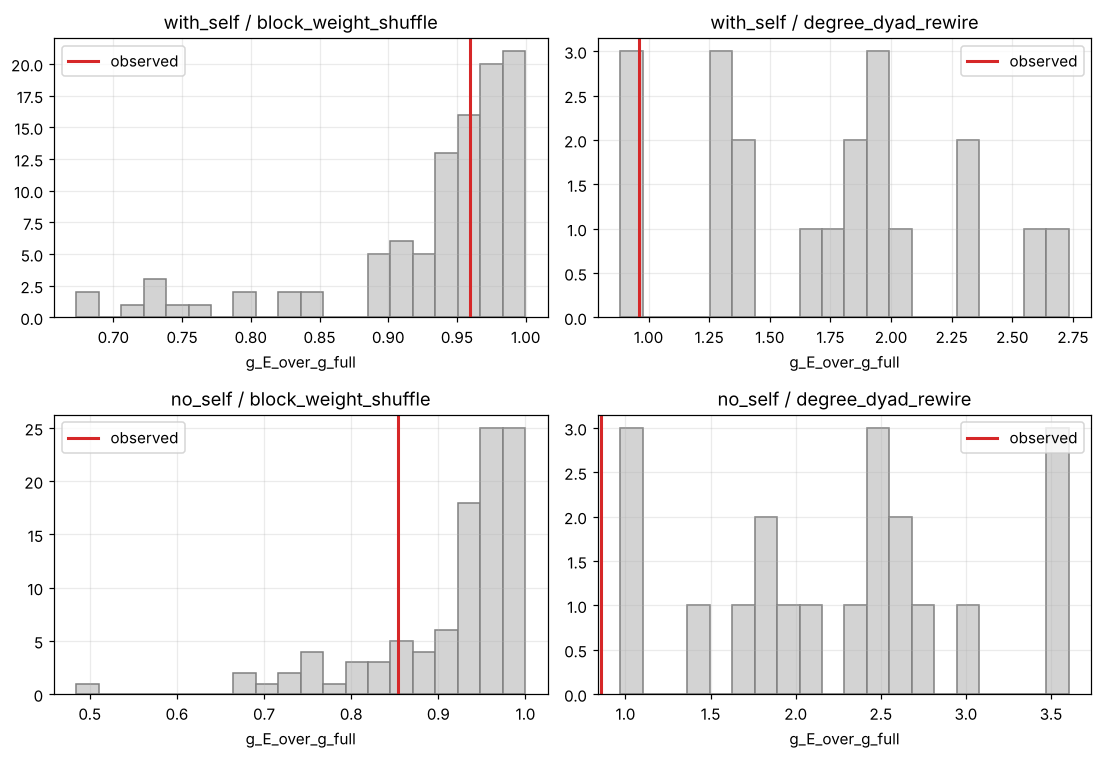

In [17]:
N_NULL = {"block_weight_shuffle": 100, "degree_dyad_rewire": 20}
obs = {v: ip.isn_profile(net, W) for v, W in VARIANTS.items()}
null_rows = []
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, v in enumerate(VARIANTS):
    for j, (kind, n) in enumerate(N_NULL.items()):
        nl = ip.null_ensemble(net, v, kind=kind, n=n, seed=2)
        save(nl, f"null_{kind}_{v}")
        ip.plot_null(nl, obs[v], "g_E_over_g_full", ax=axes[i, j]); axes[i, j].set_title(f"{v} / {kind}")
        null_rows.append({"variant": v, "null": kind, "n": n,
                          "observed g_E/g_full": obs[v]["g_E_over_g_full"],
                          "null median": nl.g_E_over_g_full.median(),
                          "P(null window exists)": nl.window_exists.mean(),
                          "p (window narrower in observed)": ip.empirical_p(nl.g_E_over_g_full, obs[v]["g_E_over_g_full"], "lower"),
                          "observed n robust paradox": obs[v]["n_paradoxical_robust"],
                          "null mean n robust paradox": nl.n_paradoxical_robust.mean()})
plt.tight_layout(); plt.savefig(OUT / "null_window.png", bbox_inches="tight")
null_summary = pd.DataFrame(null_rows); save(null_summary, "null_summary"); null_summary

### 4.4 Inhibitory time constant

$\Gamma$ does not depend on τ, but stability can (Hopf). Slow inhibition can
make a paradoxical steady state unreachable. Swap in per-type $\tau_m$
(`tau_m_85_updated.csv`, not in this repo) through `jc.build_jacobian(tau=...)`
when available.

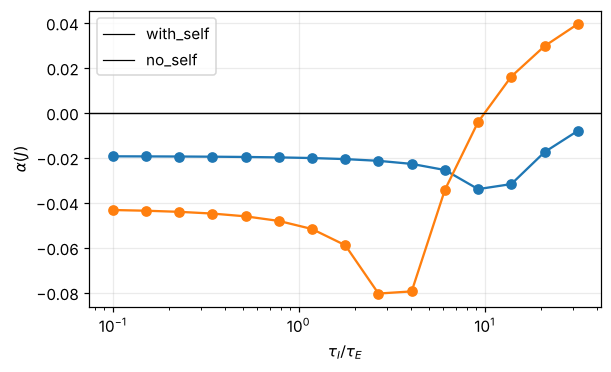

In [18]:
ratios = np.logspace(-1, 1.5, 15)
fig, ax = plt.subplots(figsize=(6, 3.5))
for v, W in VARIANTS.items():
    df = ip.tau_ratio_sweep(net, W, G_REF[v], ratios); save(df, f"tau_ratio_{v}")
    ip.plot_tau_ratio(df, ax=ax); ax.lines[-1].set_label(v)
ax.legend(); plt.savefig(OUT / "tau_ratio.png", bbox_inches="tight")

### 4.5 Short-term plasticity - not implemented

$m_{ij}$ excludes STP. E→E depression or E→I facilitation can stabilise without
inhibition and decouple ISN from paradox (Wu & Zenke 2021). Extension:
linearise Tsodyks-Markram synapses (Hippocampome $U$, $\tau_r$, $\tau_f$) at the
operating rates into effective gains, then rerun Phases 1-3.

## Phase 5 - State dependence and rectification

### 5.1 ISN status vs baseline activity (power-law transfer)

With $f(u) = u^n$ the local gain grows with rate. Baselines are $r_E = s$ and
$r_I = \text{ratio}\cdot s$. Uniform rates would reduce to $g$ scaling; heterogeneous
rates move the E/I gain balance with activity.

In [19]:
scales = np.logspace(-1, 1, 401)
rows = []
for v, W in VARIANTS.items():
    for ratio in (1, 3, 10, 30):
        df = ip.rate_dependent_isn(net, W, 0.9, scales, ratio_I_to_E=ratio)
        isn = df[df.ISN]
        span = np.flatnonzero(df.ISN.to_numpy())
        rows.append({"variant": v, "rI/rE": ratio,
                     "ISN from s": isn.rate_scale.min() if len(isn) else np.nan,
                     "ISN to s": isn.rate_scale.max() if len(isn) else np.nan,
                     "contiguous": bool(len(span) and span[-1] - span[0] + 1 == len(span))})
rate_isn = pd.DataFrame(rows); save(rate_isn, "rate_dependent_isn"); rate_isn

,variant,rI/rE,ISN from s,ISN to s,contiguous
0,with_self,1,1.1482,1.2303,True
1,with_self,3,1.1482,1.2882,True
2,with_self,10,1.1482,1.3964,True
3,with_self,30,1.1482,1.5311,True
4,no_self,1,0.9016,1.2303,True
5,no_self,3,0.9016,1.6788,True
6,no_self,10,0.9016,6.9183,True
7,no_self,30,0.9016,3.3497,True


### 5.2 Rectified (threshold-linear) model

Does rectification (types silenced by the drive) abolish the linear paradox?
Baseline rates are all 1, a uniform operating point, and amplitudes are in the
same units. Wherever the linear prediction drives a rate below zero
(`linear_delta` < −1 for a single type), rectification must take over. Compare
`nonlinear_delta` with `linear_delta` as the step amplitude grows.

In [20]:
for v, W in VARIANTS.items():
    targets = {k: [k] for k in at_ref[v]}
    targets["all_I"] = SETS["all_I"]
    df = ip.nonlinear_step_table(net, W, G_REF[v], targets, amplitudes=[0.1, 0.5, 1, 2, 5])
    save(df, f"rectified_steps_{v}"); print(v); display(df)

with_self


,set,amplitude,nonlinear_delta,linear_delta,n_types_silenced,max_rate_over_baseline,converged
0,MEC LIII Superficial Multipolar Interneuron,0.1,-0.0610,-0.0611,0,1.0023,True
1,MEC LIII Superficial Multipolar Interneuron,0.5,-0.3052,-0.3055,0,1.0114,True
2,MEC LIII Superficial Multipolar Interneuron,1.0,-0.6108,-0.6110,1,1.0227,True
3,MEC LIII Superficial Multipolar Interneuron,2.0,-1.0000,-1.2219,24,0.9889,False
4,MEC LIII Superficial Multipolar Interneuron,5.0,-1.0000,-3.0548,24,0.9889,True
5,all_I,0.1,-0.2440,-0.2452,0,1.0993,True
6,all_I,0.5,-19.5482,-1.2259,19,1.4874,True
7,all_I,1.0,-4.2775,-2.4518,17,1.9859,True
8,all_I,2.0,28.1544,-4.9037,17,2.9831,True
9,all_I,5.0,130.4643,-12.2592,19,5.9744,True


no_self


,set,amplitude,nonlinear_delta,linear_delta,n_types_silenced,max_rate_over_baseline,converged
0,MEC LIII Superficial Multipolar Interneuron,0.1,-0.1215,-0.1216,0,1.0186,True
1,MEC LIII Superficial Multipolar Interneuron,0.5,-0.6255,-0.6081,3,1.0887,True
2,MEC LIII Superficial Multipolar Interneuron,1.0,-1.0000,-1.2162,53,0.9823,True
3,MEC LIII Superficial Multipolar Interneuron,2.0,-1.0000,-2.4324,53,0.9823,True
4,MEC LIII Superficial Multipolar Interneuron,5.0,-1.0000,-6.0811,53,0.9823,True
5,all_I,0.1,-44.1920,-17.8363,53,1.0820,True
6,all_I,0.5,-38.9020,-89.1813,48,1.4808,True
7,all_I,1.0,-30.4865,-178.3627,47,1.9792,True
8,all_I,2.0,-10.6944,-356.7253,42,2.9761,True
9,all_I,5.0,61.1976,-891.8133,37,5.9627,True


## Phase 6 - Predictions

One row per robustly paradoxical type: onset gain, whether it is already
paradoxical at `G_REF`, mechanism (3.4, at `G_REF`) and transient shape (3.6).
Rows with `paradoxical_at_g_ref` are checkable optogenetic experiments; the
others say how much more gain they would need.

In [21]:
for v, W in VARIANTS.items():
    dec = ip.path_decomposition(net, W, G_REF[v], {k: [k] for k in onsets[v].index[onsets[v].robust_paradox]})
    pred = ip.prediction_table(onsets[v], dec, steps[v], G_REF[v])
    save(pred, f"predictions_{v}"); print(v); display(pred)

with_self


,onset_gain,onset_over_g_full,paradoxical_before_g_full,robust_paradox,n_crossings_before_g_full,region,i_class,paradoxical_at_g_ref,mechanism,step_shape,experiment
cell_type,,,,,,,,,,,
MEC LIII Superficial Multipolar Interneuron,0.9665,0.9665,True,True,1,MEC,other,True,ISN-type paradox (needs E loop),rise-then-dip (ISN signature),Optogenetic activation of MEC LIII Superficial...


no_self


,onset_gain,onset_over_g_full,paradoxical_before_g_full,robust_paradox,n_crossings_before_g_full,region,i_class,paradoxical_at_g_ref,mechanism,step_shape,experiment
cell_type,,,,,,,,,,,
MEC LIII Superficial Multipolar Interneuron,0.8988,0.8988,True,True,1,MEC,other,True,ISN-type paradox (needs E loop),rise-then-dip (ISN signature),Optogenetic activation of MEC LIII Superficial...
CA3 Basket,0.9893,0.9893,True,True,1,CA3,basket,False,not paradoxical,,Not paradoxical at g = 0.95; becomes so above ...
MEC LIII Superficial Trilayered Interneuron,0.9893,0.9893,True,True,1,MEC,other,False,not paradoxical,,Not paradoxical at g = 0.95; becomes so above ...
CA1 Back Projection,0.9899,0.9899,True,True,1,CA1,projecting,False,not paradoxical,,Not paradoxical at g = 0.95; becomes so above ...


### Literature check - TODO

For each predicted type or region, find optogenetic interneuron-activation
studies in CA1, CA3, DG and MEC that recorded the stimulated population
(Sanzeni et al. 2020 is the cortical template). Then fill in the outcome table:

| Outcome | Reading |
|---|---|
| ISN window contains the principled g; paradoxical set non-empty and robust | Connectome supports an ISN regime; names the indispensable interneurons |
| ISN only for no_self / only near g → 1 | Conditional on within-type E coupling and gain |
| Never ISN at plausible g | Stability is not inhibition-dependent; consistent with the functionally feedforward thesis |
| Class-level negative responses but no robust $\Gamma_{kk} < 0$ | Multi-type decoupling of paradox from ISN |